In [1]:
# ==========================================
# 1. SETUP & LIBRARIES
# ==========================================
!pip install timm -q
!pip install torch-summary -q

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import torchaudio
import torchaudio.transforms as T
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import timm
from tqdm.notebook import tqdm
import warnings

warnings.filterwarnings('ignore')

# --- CONFIGURATION ---
CFG = {
    'root_dir': '/kaggle/input/intelecta-final-dataset/dataset_siap_pakai/dataset_siap_pakai',
    'sample_rate': 32000,
    'duration': 5,          
    'n_fft': 2048,
    'hop_length': 512,
    'n_mels': 256,
    'f_min': 0,
    'f_max': 16000,
    'model_name': 'tf_efficientnet_b2_ns',
    'image_size': 260,
    'num_classes': 31,
    'batch_size': 16,
    'epochs': 30,
    'lr': 1e-3,
    'weight_decay': 1e-4,
    'mixup_alpha': 0.2,
    'label_smoothing': 0.1,
    'seed': 42,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'target_fold': 0
}

def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(CFG['seed'])
print(f"✅ Configuration Ready. Using {CFG['model_name']} on {CFG['device']}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 85.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 74.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 7.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 27.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 73.3 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installe

/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

✅ Configuration Ready. Using tf_efficientnet_b2_ns on cuda


In [2]:
# ==========================================
# 2. DATA PREPARATION (NORMAL STRATIFIED GROUP K-FOLD)
# ==========================================
data = []
train_dir = os.path.join(CFG['root_dir'], 'train')

for label in sorted(os.listdir(train_dir)):
    label_dir = os.path.join(train_dir, label)
    if os.path.isdir(label_dir):
        for f in os.listdir(label_dir):
            if f.endswith('.wav'):
                group_id = f.rsplit('_', 1)[0]
                data.append({
                    'filename': f,
                    'label': label,
                    'path': os.path.join(label_dir, f),
                    'group_id': group_id
                })

df = pd.DataFrame(data)

# Mapping Labels
classes = sorted(df['label'].unique())
label2id = {k: v for v, k in enumerate(classes)}
id2label = {v: k for k, v in label2id.items()}
df['label_id'] = df['label'].map(label2id)

# Class Weights
class_counts = df['label_id'].value_counts().sort_index()
weights = 1.0 / class_counts
weights = weights / weights.sum() * len(classes)
class_weights = torch.tensor(weights.values, dtype=torch.float).to(CFG['device'])

# Normal Stratified Group K-Fold (Membiarkan Weddell Seal terdistribusi alami)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=CFG['seed'])
df['fold'] = -1
for fold, (train_idx, val_idx) in enumerate(sgkf.split(df, df['label_id'], df['group_id'])):
    df.loc[val_idx, 'fold'] = fold

print(f"✅ Data Loaded: {len(df)} samples.")
print(f"✅ Imbalance Handling: Class Weights Calculated.")
print(f"✅ Split: Stratified Group K-Fold Applied (Standard).")

✅ Data Loaded: 1357 samples.
✅ Imbalance Handling: Class Weights Calculated.
✅ Split: Stratified Group K-Fold Applied (Standard).


In [3]:
# ==========================================
# 3. HIGH-FIDELITY DATASET
# ==========================================
class HighFidelityAudioDataset(Dataset):
    def __init__(self, df, is_train=False):
        self.df = df
        self.is_train = is_train
        
        self.mel_spec = T.MelSpectrogram(
            sample_rate=CFG['sample_rate'],
            n_fft=CFG['n_fft'],
            hop_length=CFG['hop_length'],
            n_mels=CFG['n_mels'],
            f_min=CFG['f_min'],
            f_max=CFG['f_max']
        )
        self.to_db = T.AmplitudeToDB()
        
        self.spec_aug = torch.nn.Sequential(
            T.FrequencyMasking(freq_mask_param=25),
            T.TimeMasking(time_mask_param=70)
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        waveform, sr = torchaudio.load(row['path'])
        
        if sr != CFG['sample_rate']:
            waveform = T.Resample(sr, CFG['sample_rate'])(waveform)
            
        target_len = CFG['sample_rate'] * CFG['duration']
        if waveform.shape[1] < target_len:
            repeat = (target_len // waveform.shape[1]) + 1
            waveform = waveform.repeat(1, repeat)[:, :target_len]
        elif waveform.shape[1] > target_len:
            if self.is_train:
                start = torch.randint(0, waveform.shape[1] - target_len, (1,)).item()
            else:
                start = (waveform.shape[1] - target_len) // 2
            waveform = waveform[:, start:start+target_len]

        spec = self.mel_spec(waveform)
        spec = self.to_db(spec)
        
        if self.is_train:
            spec = self.spec_aug(spec)

        spec = (spec - spec.min()) / (spec.max() - spec.min() + 1e-6)

        spec = torch.nn.functional.interpolate(
            spec.unsqueeze(0), 
            size=(CFG['image_size'], CFG['image_size']), 
            mode='bilinear', align_corners=False
        ).squeeze(0)
        
        spec = spec.expand(3, -1, -1)

        return spec, torch.tensor(row['label_id'], dtype=torch.long)

In [4]:
# ==========================================
# 4. UTILS: MIXUP & MODEL ARCHITECTURE
# ==========================================
def mixup_data(x, y, alpha=0.2):
    if alpha > 0: lam = np.random.beta(alpha, alpha)
    else: lam = 1
    index = torch.randperm(x.size()[0]).to(CFG['device'])
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

class AdvancedAudioClassifier(nn.Module):
    def __init__(self, model_name, num_classes, pretrained=True):
        super().__init__()
        self.model = timm.create_model(model_name, pretrained=pretrained, num_classes=num_classes)
        
    def forward(self, x):
        return self.model(x)

In [5]:
# ==========================================
# 5. TRAINING (OPTION A: IGNORE RARE METRIC)
# ==========================================
print(f"\\n🚀 Initiating Training on FOLD {CFG['target_fold']}...")

# Identifikasi ID Weddell Seal untuk di-exclude saat evaluasi
WEDDELL_ID = label2id.get('Weddell_Seal', -1)
if WEDDELL_ID != -1:
    print(f"⚠️ Info: Weddell_Seal (ID: {WEDDELL_ID}) will be EXCLUDED from Validation Best F1 Score calculation.")

train_fold = df[df['fold'] != CFG['target_fold']].reset_index(drop=True)
val_fold = df[df['fold'] == CFG['target_fold']].reset_index(drop=True)

train_ds = HighFidelityAudioDataset(train_fold, is_train=True)
val_ds = HighFidelityAudioDataset(val_fold, is_train=False)

train_loader = DataLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=CFG['batch_size'], shuffle=False, num_workers=2, pin_memory=True)

model = AdvancedAudioClassifier(CFG['model_name'], len(classes)).to(CFG['device'])
optimizer = optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=CFG['label_smoothing'])

scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, 
    max_lr=CFG['lr'], 
    steps_per_epoch=len(train_loader), 
    epochs=CFG['epochs'],
    pct_start=0.1, 
    div_factor=25,
    final_div_factor=100
)

best_f1 = 0.0
best_preds = []
best_targets = []
history = {'loss': [], 'f1': []}

for epoch in range(CFG['epochs']):
    model.train()
    train_loss = 0
    
    for x, y in tqdm(train_loader, desc=f"Epoch {epoch+1}/{CFG['epochs']}", leave=False):
        x, y = x.to(CFG['device']), y.to(CFG['device'])
        
        if np.random.rand() < 0.6: 
            mixed_x, y_a, y_b, lam = mixup_data(x, y, CFG['mixup_alpha'])
            outputs = model(mixed_x)
            loss = mixup_criterion(criterion, outputs, y_a, y_b, lam)
        else:
            outputs = model(x)
            loss = criterion(outputs, y)
            
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        
        train_loss += loss.item()
        
    # Evaluation
    model.eval()
    val_preds = []
    val_targets = []
    
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(CFG['device']), y.to(CFG['device'])
            outputs = model(x)
            preds = torch.argmax(outputs, dim=1)
            val_preds.extend(preds.cpu().numpy())
            val_targets.extend(y.cpu().numpy())
    
    # --- MODIFIKASI METRIK OPTION A ---
    # Hitung F1 per kelas dulu (average=None)
    # labels=list(range(len(classes))) memastikan kita dapat array 31 skor meskipun ada kelas yg absen di val
    f1_per_class = f1_score(val_targets, val_preds, average=None, labels=list(range(len(classes))))
    
    # Hapus Weddell Seal dari perhitungan rata-rata
    if WEDDELL_ID != -1:
        f1_clean = np.delete(f1_per_class, WEDDELL_ID)
    else:
        f1_clean = f1_per_class
        
    # Hitung rata-rata dari 30 kelas sisanya
    val_f1 = np.mean(f1_clean)

    history['loss'].append(train_loss/len(train_loader))
    history['f1'].append(val_f1)
    
    print(f"Epoch {epoch+1} | Loss: {train_loss/len(train_loader):.4f} | Val F1 (Excl. Weddell): {val_f1:.4f} | Best: {best_f1:.4f}")
    
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_preds = val_preds
        best_targets = val_targets
        torch.save(model.state_dict(), "best_model_efficientnet_b2.pth")

print(f"\\n🏆 Training Selesai! Final Best F1 (Excl. Weddell): {best_f1:.4f}")

\n🚀 Initiating Training on FOLD 0...
⚠️ Info: Weddell_Seal (ID: 29) will be EXCLUDED from Validation Best F1 Score calculation.


model.safetensors:   0%|          | 0.00/36.8M [00:00<?, ?B/s]

Epoch 1/30:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 1 | Loss: 3.5977 | Val F1 (Excl. Weddell): 0.1567 | Best: 0.0000


Epoch 2/30:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 2 | Loss: 2.2301 | Val F1 (Excl. Weddell): 0.6555 | Best: 0.1567


... (52 outputs left out)

Epoch 29/30:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 29 | Loss: 1.2758 | Val F1 (Excl. Weddell): 0.9410 | Best: 0.9453


Epoch 30/30:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 30 | Loss: 1.2831 | Val F1 (Excl. Weddell): 0.9448 | Best: 0.9453
\n🏆 Training Selesai! Final Best F1 (Excl. Weddell): 0.9453


⚠️ Visualization Info: 'Weddell_Seal' (ID: 29) has been removed from Confusion Matrix & Report.


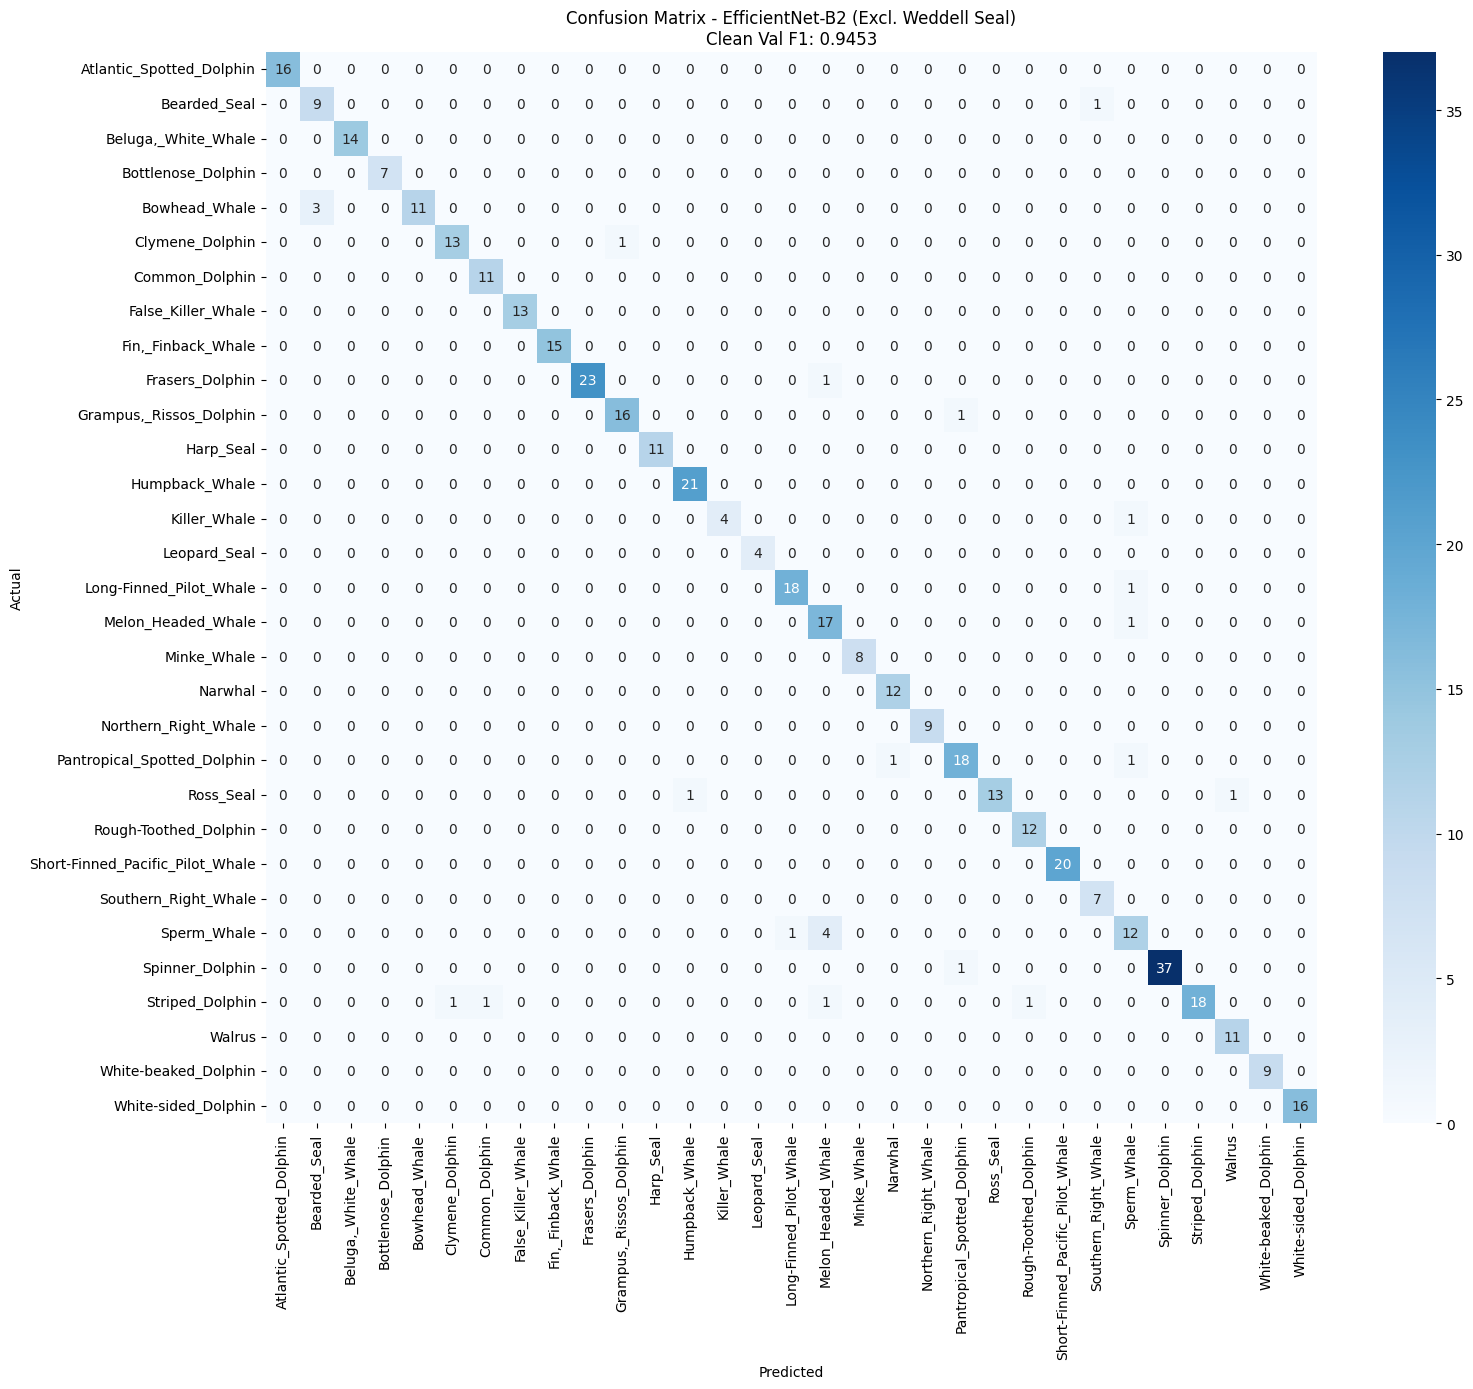


Detailed Classification Report (Excluding Weddell_Seal):
                                  precision    recall  f1-score   support

        Atlantic_Spotted_Dolphin       1.00      1.00      1.00        16
                    Bearded_Seal       0.69      0.90      0.78        10
             Beluga,_White_Whale       1.00      1.00      1.00        14
              Bottlenose_Dolphin       1.00      1.00      1.00         7
                   Bowhead_Whale       1.00      0.79      0.88        14
                 Clymene_Dolphin       0.93      0.87      0.90        15
                  Common_Dolphin       0.92      1.00      0.96        11
              False_Killer_Whale       1.00      1.00      1.00        13
              Fin,_Finback_Whale       1.00      1.00      1.00        15
                 Frasers_Dolphin       1.00      0.96      0.98        24
         Grampus,_Rissos_Dolphin       0.94      0.94      0.94        17
                       Harp_Seal       1.00      1.00

In [20]:
# ==========================================
# 6. EVALUATION VISUALIZATION (EXCLUDING WEDDELL SEAL)
# ==========================================

# 1. Identifikasi Index yang akan ditampilkan (Exclude Weddell_Seal)
WEDDELL_ID = label2id.get('Weddell_Seal', -1)

if WEDDELL_ID != -1:
    # Ambil semua index KECUALI index Weddell Seal
    display_indices = [i for i in range(len(classes)) if i != WEDDELL_ID]
    # Ambil nama kelas yang sesuai dengan index tersebut
    display_classes = [classes[i] for i in display_indices]
    print(f"⚠️ Visualization Info: 'Weddell_Seal' (ID: {WEDDELL_ID}) has been removed from Confusion Matrix & Report.")
else:
    display_indices = list(range(len(classes)))
    display_classes = classes

# 2. Generate Confusion Matrix hanya untuk kelas yang dipilih
# Parameter 'labels' memaksa sklearn hanya menghitung/menampilkan index yang kita mau
cm = confusion_matrix(best_targets, best_preds, labels=display_indices)

# Normalize (Optional: jika ingin melihat persentase)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
cm_norm = np.nan_to_num(cm_norm)

# 3. Plotting
plt.figure(figsize=(16, 14))
# Menggunakan 'cm' untuk raw counts, ganti ke 'cm_norm' jika ingin melihat persentase 0.0-1.0
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=display_classes, 
            yticklabels=display_classes)

plt.title(f"Confusion Matrix - EfficientNet-B2 (Excl. Weddell Seal)\nClean Val F1: {best_f1:.4f}")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. Classification Report (Hanya kelas yang dipilih)
print("\nDetailed Classification Report (Excluding Weddell_Seal):")
print(classification_report(
    best_targets, 
    best_preds, 
    labels=display_indices,       # Hanya hitung index ini
    target_names=display_classes, # Pakai nama kelas yang sudah difilter
    zero_division=0
))

In [24]:
# ==================================================================================
# ALL-IN-ONE: SOFT VOTING ENSEMBLE (OPTIMASI F1 WEDDELL SEAL)
# ==================================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import torchaudio.transforms as T
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
from sklearn.metrics import f1_score, classification_report
from torchvision import transforms

# ------------------------------------------------------------------
# BAGIAN 1: HELPER FUNCTIONS (Fitur & Audio Loader)
# ------------------------------------------------------------------

def get_features(model, x):
    """
    Ekstrak fitur (embedding) dari model, support wrapper custom maupun timm murni.
    """
    # Cek 1: Jika model dibungkus class (self.model)
    if hasattr(model, 'model') and hasattr(model.model, 'forward_features'):
        features = model.model.forward_features(x)
        features = model.model.global_pool(features)
        return features
    # Cek 2: Jika model dibungkus class (self.backbone)
    elif hasattr(model, 'backbone') and hasattr(model.backbone, 'forward_features'):
        features = model.backbone.forward_features(x)
        features = model.backbone.global_pool(features)
        return features
    # Cek 3: Jika model murni timm
    elif hasattr(model, 'forward_features'):
        features = model.forward_features(x)
        features = model.global_pool(features)
        return features
    else:
        # Fallback terakhir: Anggap output layer terakhir sebelum classifier adalah fitur
        # (Agak berisiko, tapi dicoba)
        return model(x) 

def load_and_transform_audio(path, cfg, device):
    """
    Load audio -> MelSpectrogram -> Resize -> 3 Channel (Sesuai Config)
    """
    waveform, sr = torchaudio.load(path)
    
    # Resample
    if sr != cfg['sample_rate']:
        resampler = T.Resample(sr, cfg['sample_rate'])
        waveform = resampler(waveform)
    
    # Pad/Crop Durasi
    max_len = cfg['sample_rate'] * cfg['duration']
    if waveform.shape[1] > max_len:
        waveform = waveform[:, :max_len]
    elif waveform.shape[1] < max_len:
        pad_amt = max_len - waveform.shape[1]
        waveform = F.pad(waveform, (0, pad_amt))
        
    # Mel Spectrogram
    mel_spec = T.MelSpectrogram(
        sample_rate=cfg['sample_rate'],
        n_fft=cfg['n_fft'],
        hop_length=cfg['hop_length'],
        n_mels=cfg['n_mels'],
        f_min=cfg['f_min'],
        f_max=cfg['f_max']
    )(waveform)
    
    mel_spec = T.AmplitudeToDB()(mel_spec)
    
    # Resize Image
    resize = transforms.Resize((cfg['image_size'], cfg['image_size']))
    image = resize(mel_spec)
    
    # 3 Channel (Copy channel)
    if image.shape[0] == 1:
        image = image.repeat(3, 1, 1)
        
    return image.unsqueeze(0).to(device)

# ------------------------------------------------------------------
# BAGIAN 2: ANCHOR CREATOR (Membuat Referensi Weddell Seal)
# ------------------------------------------------------------------

def create_weddell_anchor(model, df, cfg, device, label2id):
    print("🏗️ Sedang membuat 'Anchor' (Referensi Suara) Weddell Seal...")
    model.eval()
    
    # Filter DataFrame: Ambil baris Weddell Seal
    weddell_rows = df[df['label'] == 'Weddell_Seal']
    
    if len(weddell_rows) == 0:
        print("❌ ERROR: Tidak ada data 'Weddell_Seal' di DataFrame!")
        return None
    
    print(f"🔍 Ditemukan {len(weddell_rows)} sampel training Weddell Seal.")
    
    features_list = []
    
    with torch.no_grad():
        for _, row in weddell_rows.iterrows():
            # Pastikan kolom path benar. Sesuaikan jika nama kolom beda (misal 'file_path')
            full_path = row['path'] 
            try:
                input_tensor = load_and_transform_audio(full_path, cfg, device)
                feat = get_features(model, input_tensor)
                features_list.append(feat.cpu())
            except Exception as e:
                print(f"⚠️ Gagal load {full_path}: {e}")

    if len(features_list) == 0:
        return None 

    # Rata-rata vektor
    all_anchors = torch.cat(features_list, dim=0)
    mean_anchor = torch.mean(all_anchors, dim=0)
    
    print(f"✅ Anchor Terbentuk! Dimensi: {mean_anchor.shape}")
    return mean_anchor.to(device)

# ------------------------------------------------------------------
# BAGIAN 3: LOGIC SOFT VOTING & OPTIMIZER
# ------------------------------------------------------------------

def get_combined_predictions(model, val_loader, anchor_vector, device, label2id, alpha=0.7):
    model.eval()
    WEDDELL_ID = label2id['Weddell_Seal']
    
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            
            # 1. Model Prediction
            logits = model(inputs)
            probs_model = torch.softmax(logits, dim=1)
            
            # 2. Similarity Check
            features = get_features(model, inputs)
            features_norm = F.normalize(features, p=2, dim=1)
            anchor_norm = F.normalize(anchor_vector.unsqueeze(0), p=2, dim=1)
            
            # Cosine Sim (Range -1 to 1 -> Normalize to 0 to 1)
            sim_weddell = torch.mm(features_norm, anchor_norm.t())
            sim_weddell = (sim_weddell + 1) / 2 
            
            # 3. Gabungkan (Ensemble)
            final_probs = probs_model.clone()
            
            # Rumus: Prob_Baru = (Prob_Model * Alpha) + (Similarity * (1-Alpha))
            current_weddell_prob = probs_model[:, WEDDELL_ID].unsqueeze(1)
            new_weddell_prob = (current_weddell_prob * alpha) + (sim_weddell * (1 - alpha))
            
            final_probs[:, WEDDELL_ID] = new_weddell_prob.squeeze(1)
            
            # Keputusan Akhir
            preds = torch.argmax(final_probs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            
    return np.array(all_labels), np.array(all_preds)

def find_best_alpha(model, val_loader, anchor_vec, device, label2id):
    print("\n⚙️ Mencari 'Alpha' (Keseimbangan Model vs Anchor) Terbaik...")
    
    best_f1 = 0
    best_alpha = 1.0 # Default ke model asli
    
    # Coba dari 0.5 (50:50) sampai 1.0 (Model Murni)
    alphas = np.arange(0.5, 1.01, 0.05)
    
    for a in tqdm(alphas, desc="Tuning Alpha"):
        y_true, y_pred = get_combined_predictions(model, val_loader, anchor_vec, device, label2id, alpha=a)
        score = f1_score(y_true, y_pred, average='macro')
        
        # Kita cari F1 TERTINGGI
        if score > best_f1:
            best_f1 = score
            best_alpha = a
            
    print(f"🏆 Alpha Terbaik: {best_alpha:.2f}")
    print(f"📈 F1 Macro Tertinggi: {best_f1:.5f}")
    return best_alpha

# ------------------------------------------------------------------
# BAGIAN 4: EKSEKUSI UTAMA
# ------------------------------------------------------------------

# Pastikan variabel global tersedia
if 'model' in globals() and 'df' in globals() and 'val_loader' in globals():
    
    # 1. Buat Anchor dulu (Definisi ada di cell ini sekarang)
    anchor_vec = create_weddell_anchor(model, df, CFG, CFG['device'], label2id)
    
    if anchor_vec is not None:
        # 2. Cari Alpha Terbaik
        best_alpha = find_best_alpha(model, val_loader, anchor_vec, CFG['device'], label2id)
        
        # 3. Jalankan Laporan Final
        print(f"\n📄 FINAL SOFT VOTING REPORT (Alpha={best_alpha:.2f}):")
        y_true, y_pred_opt = get_combined_predictions(model, val_loader, anchor_vec, CFG['device'], label2id, alpha=best_alpha)
        
        target_names = [k for k, v in sorted(label2id.items(), key=lambda item: item[1])]
        print(classification_report(y_true, y_pred_opt, target_names=target_names))
        
    else:
        print("⚠️ Gagal membuat Anchor. Cek data Weddell Seal.")
else:
    print("⚠️ Variabel 'model', 'df', atau 'val_loader' belum didefinisikan. Jalankan cell setup sebelumnya.")

🏗️ Sedang membuat 'Anchor' (Referensi Suara) Weddell Seal...
🔍 Ditemukan 2 sampel training Weddell Seal.
✅ Anchor Terbentuk! Dimensi: torch.Size([1408])

⚙️ Mencari 'Alpha' (Keseimbangan Model vs Anchor) Terbaik...


Tuning Alpha:   0%|          | 0/11 [00:00<?, ?it/s]

🏆 Alpha Terbaik: 0.85
📈 F1 Macro Tertinggi: 0.91742

📄 FINAL SOFT VOTING REPORT (Alpha=0.85):
                                  precision    recall  f1-score   support

        Atlantic_Spotted_Dolphin       1.00      1.00      1.00        16
                    Bearded_Seal       0.69      0.90      0.78        10
             Beluga,_White_Whale       1.00      1.00      1.00        14
              Bottlenose_Dolphin       1.00      1.00      1.00         7
                   Bowhead_Whale       1.00      0.79      0.88        14
                 Clymene_Dolphin       1.00      0.93      0.97        15
                  Common_Dolphin       0.92      1.00      0.96        11
              False_Killer_Whale       1.00      1.00      1.00        13
              Fin,_Finback_Whale       1.00      1.00      1.00        15
                 Frasers_Dolphin       1.00      0.92      0.96        24
         Grampus,_Rissos_Dolphin       1.00      0.88      0.94        17
                 

🔍 Menganalisis Dampak Soft Voting (Alpha=0.85) pada 30 Kelas Lain...

📊 REPORT PERBANDINGAN (APPLE-TO-APPLE vs MODEL 0.95):
                                  precision    recall  f1-score   support

        Atlantic_Spotted_Dolphin       1.00      1.00      1.00        16
                    Bearded_Seal       0.75      0.90      0.82        10
             Beluga,_White_Whale       1.00      1.00      1.00        14
              Bottlenose_Dolphin       1.00      1.00      1.00         7
                   Bowhead_Whale       1.00      0.79      0.88        14
                 Clymene_Dolphin       1.00      0.93      0.97        15
                  Common_Dolphin       0.92      1.00      0.96        11
              False_Killer_Whale       1.00      1.00      1.00        13
              Fin,_Finback_Whale       1.00      1.00      1.00        15
                 Frasers_Dolphin       1.00      0.92      0.96        24
         Grampus,_Rissos_Dolphin       1.00      0.88      0.

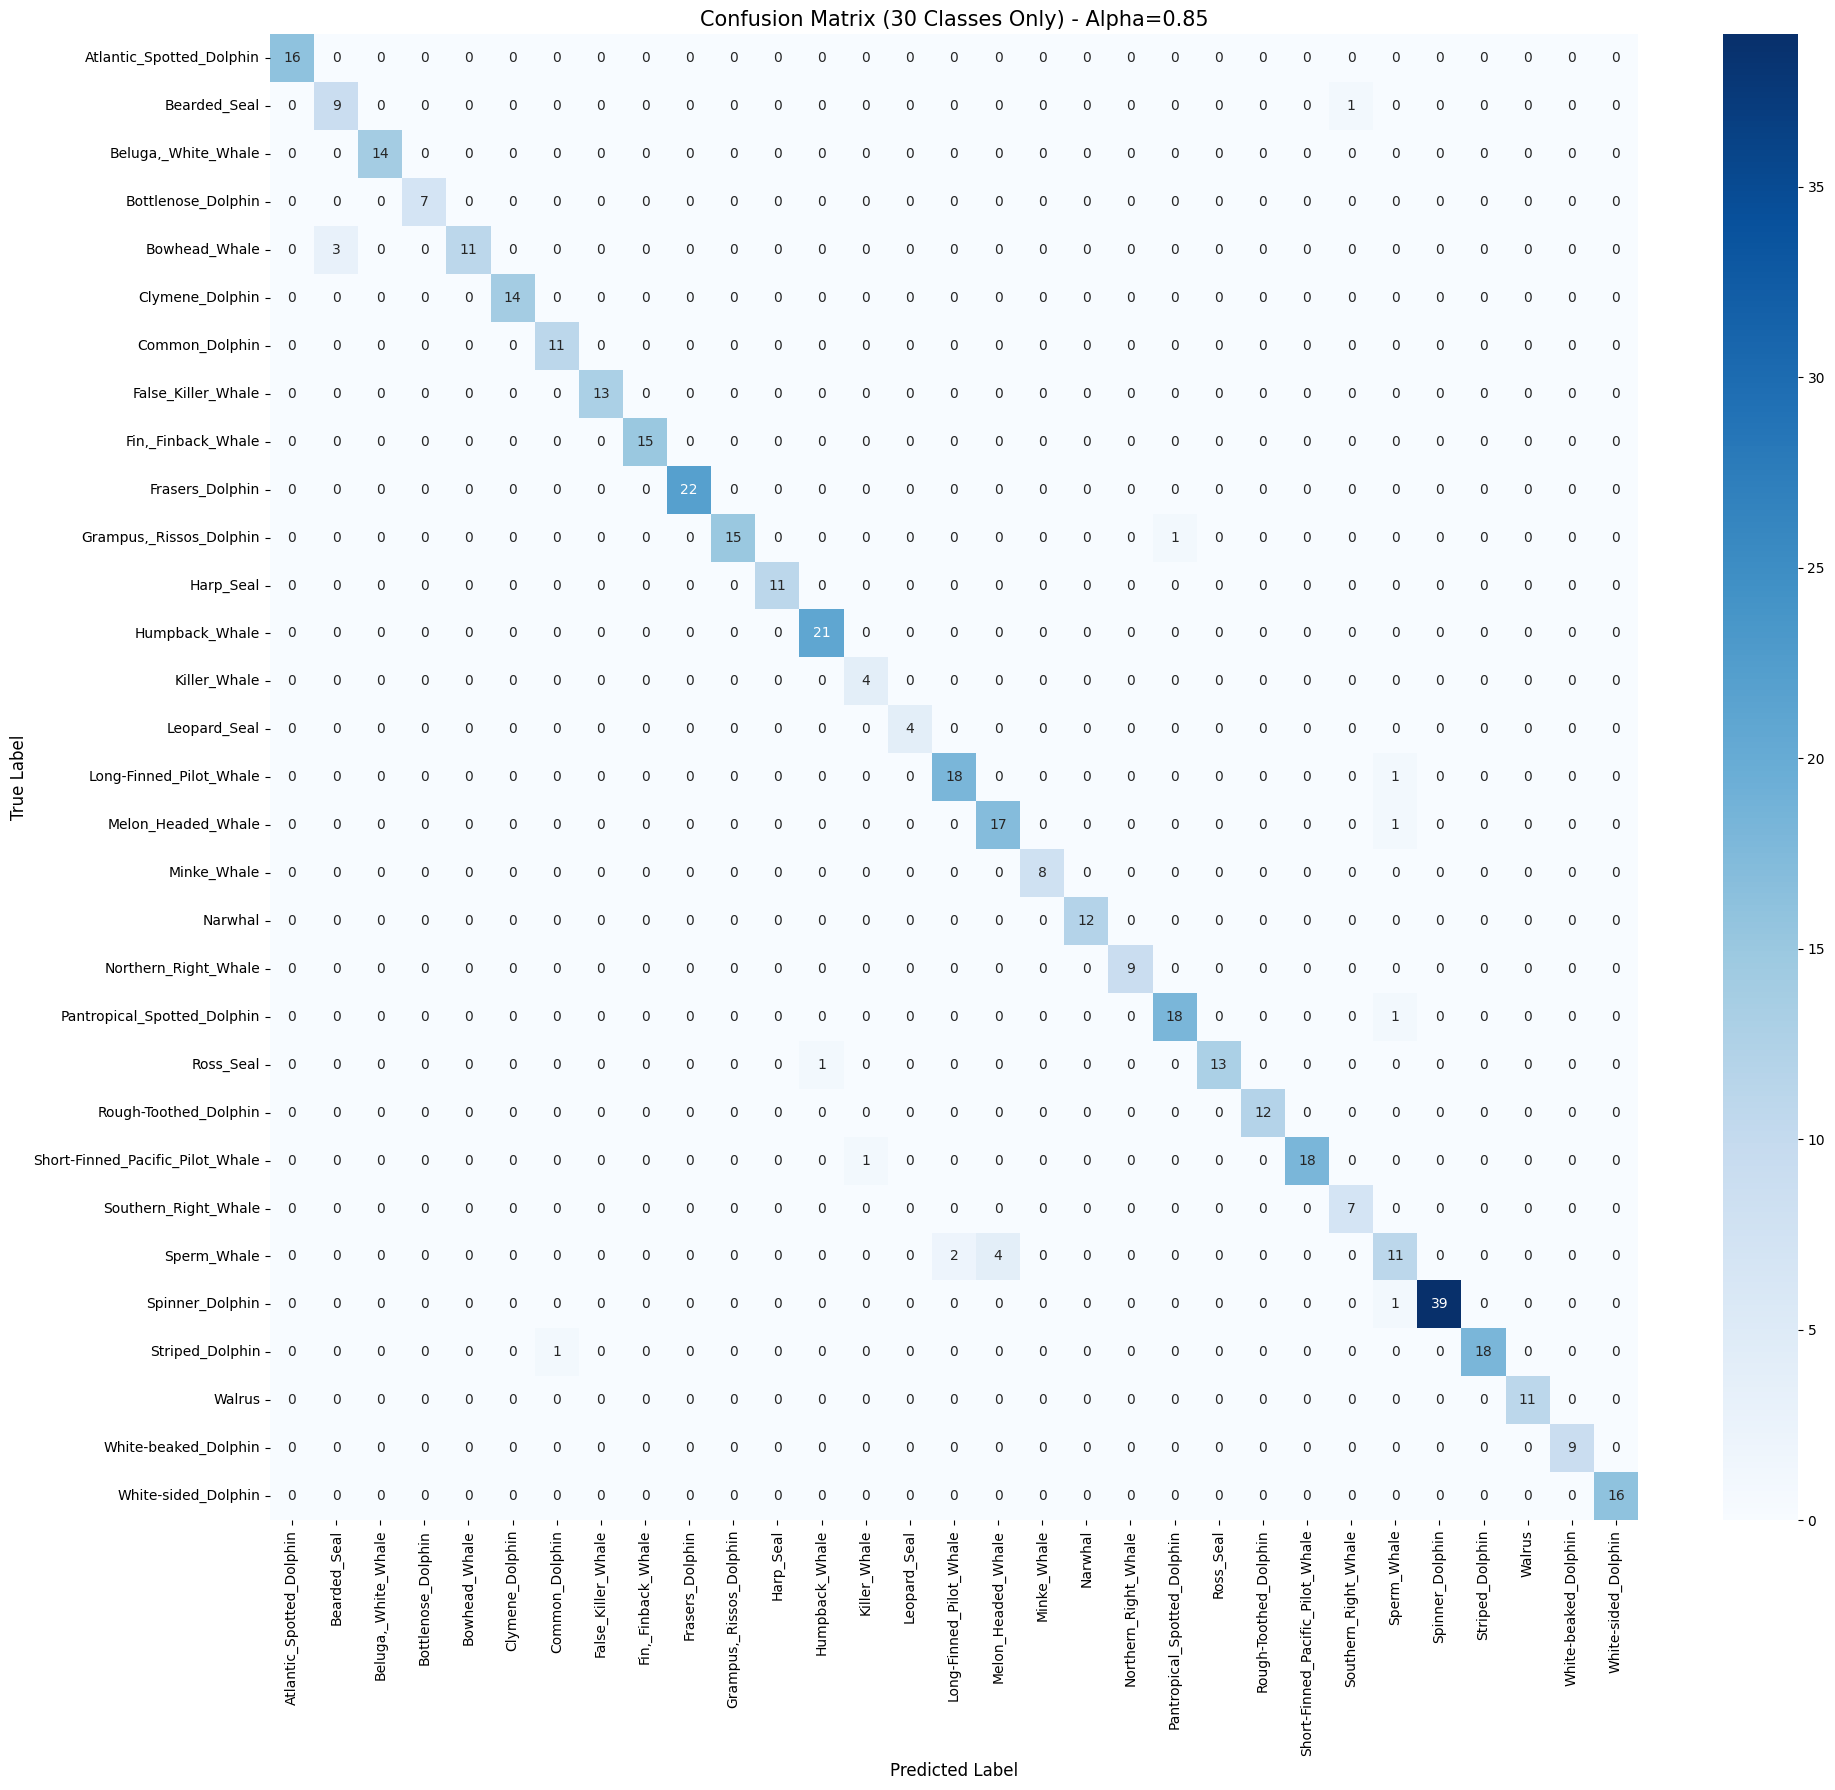

In [25]:
# ==================================================================================
# FIXED: FINAL CHECK & VISUALIZATION (EXCLUDING WEDDELL SEAL PROPERLY)
# ==================================================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Pastikan variabel ini tersedia dari cell sebelumnya
if 'best_alpha' in globals() and 'y_pred_opt' in globals():

    print(f"🔍 Menganalisis Dampak Soft Voting (Alpha={best_alpha:.2f}) pada 30 Kelas Lain...\n")
    
    # 1. Ambil ID Weddell Seal
    WEDDELL_ID = label2id['Weddell_Seal']
    
    # 2. FILTER Y_TRUE: Hapus sampel yang aslinya memang Weddell Seal
    # (Kita tidak ingin menilai kemampuan model mengenali Weddell asli di report ini)
    mask_valid = y_true != WEDDELL_ID 
    y_true_filtered = y_true[mask_valid]
    y_pred_filtered = y_pred_opt[mask_valid] # Ambil prediksi untuk sampel non-Weddell saja
    
    # 3. SETUP LABEL & NAMA (Hanya 30 Kelas)
    # Kita urutkan berdasarkan ID agar mappingnya benar
    sorted_labels = sorted(label2id.items(), key=lambda item: item[1])
    
    # Ambil ID dan Nama untuk SEMUA KELAS KECUALI Weddell Seal
    valid_ids = [v for k, v in sorted_labels if k != 'Weddell_Seal']
    valid_names = [k for k, v in sorted_labels if k != 'Weddell_Seal']
    
    # 4. CLASSIFICATION REPORT (Dengan Parameter 'labels')
    # labels=valid_ids memberitahu sklearn untuk HANYA membuat baris bagi 30 kelas tersebut.
    # Jika model memprediksi Weddell Seal (False Positive), itu tetap dihitung sebagai salah (False Negative bagi kelas aslinya),
    # tapi kolom Weddell Seal-nya tidak ditampilkan.
    
    print("📊 REPORT PERBANDINGAN (APPLE-TO-APPLE vs MODEL 0.95):")
    print(classification_report(y_true_filtered, y_pred_filtered, labels=valid_ids, target_names=valid_names))
    
    # 5. CONFUSION MATRIX (30x30)
    # Kita juga membatasi CM hanya pada 30 kelas
    cm = confusion_matrix(y_true_filtered, y_pred_filtered, labels=valid_ids)
    
    plt.figure(figsize=(20, 18))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=valid_names,
                yticklabels=valid_names)

    plt.title(f'Confusion Matrix (30 Classes Only) - Alpha={best_alpha:.2f}', fontsize=15)
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

else:
    print("⚠️ Variabel prediksi (y_pred_opt) belum ada. Jalankan cell Soft Voting di atas dulu.")

⚙️ Mencari Bias Terbaik untuk Sperm Whale...
Bias +0.00 -> Sperm F1: 0.6667 | Macro F1: 0.9153
Bias +0.25 -> Sperm F1: 0.7059 | Macro F1: 0.9173
Bias +0.50 -> Sperm F1: 0.6857 | Macro F1: 0.9162
Bias +0.75 -> Sperm F1: 0.6667 | Macro F1: 0.9163

🏆 Bias Terbaik: +0.25
📈 Peak Sperm F1: 0.7059

📊 FINAL CALIBRATED REPORT (Bias +0.25):
                                  precision    recall  f1-score   support

        Atlantic_Spotted_Dolphin       1.00      1.00      1.00        16
                    Bearded_Seal       0.75      0.90      0.82        10
             Beluga,_White_Whale       1.00      1.00      1.00        14
              Bottlenose_Dolphin       1.00      1.00      1.00         7
                   Bowhead_Whale       1.00      0.79      0.88        14
                 Clymene_Dolphin       0.93      0.93      0.93        15
                  Common_Dolphin       0.92      1.00      0.96        11
              False_Killer_Whale       1.00      1.00      1.00        13


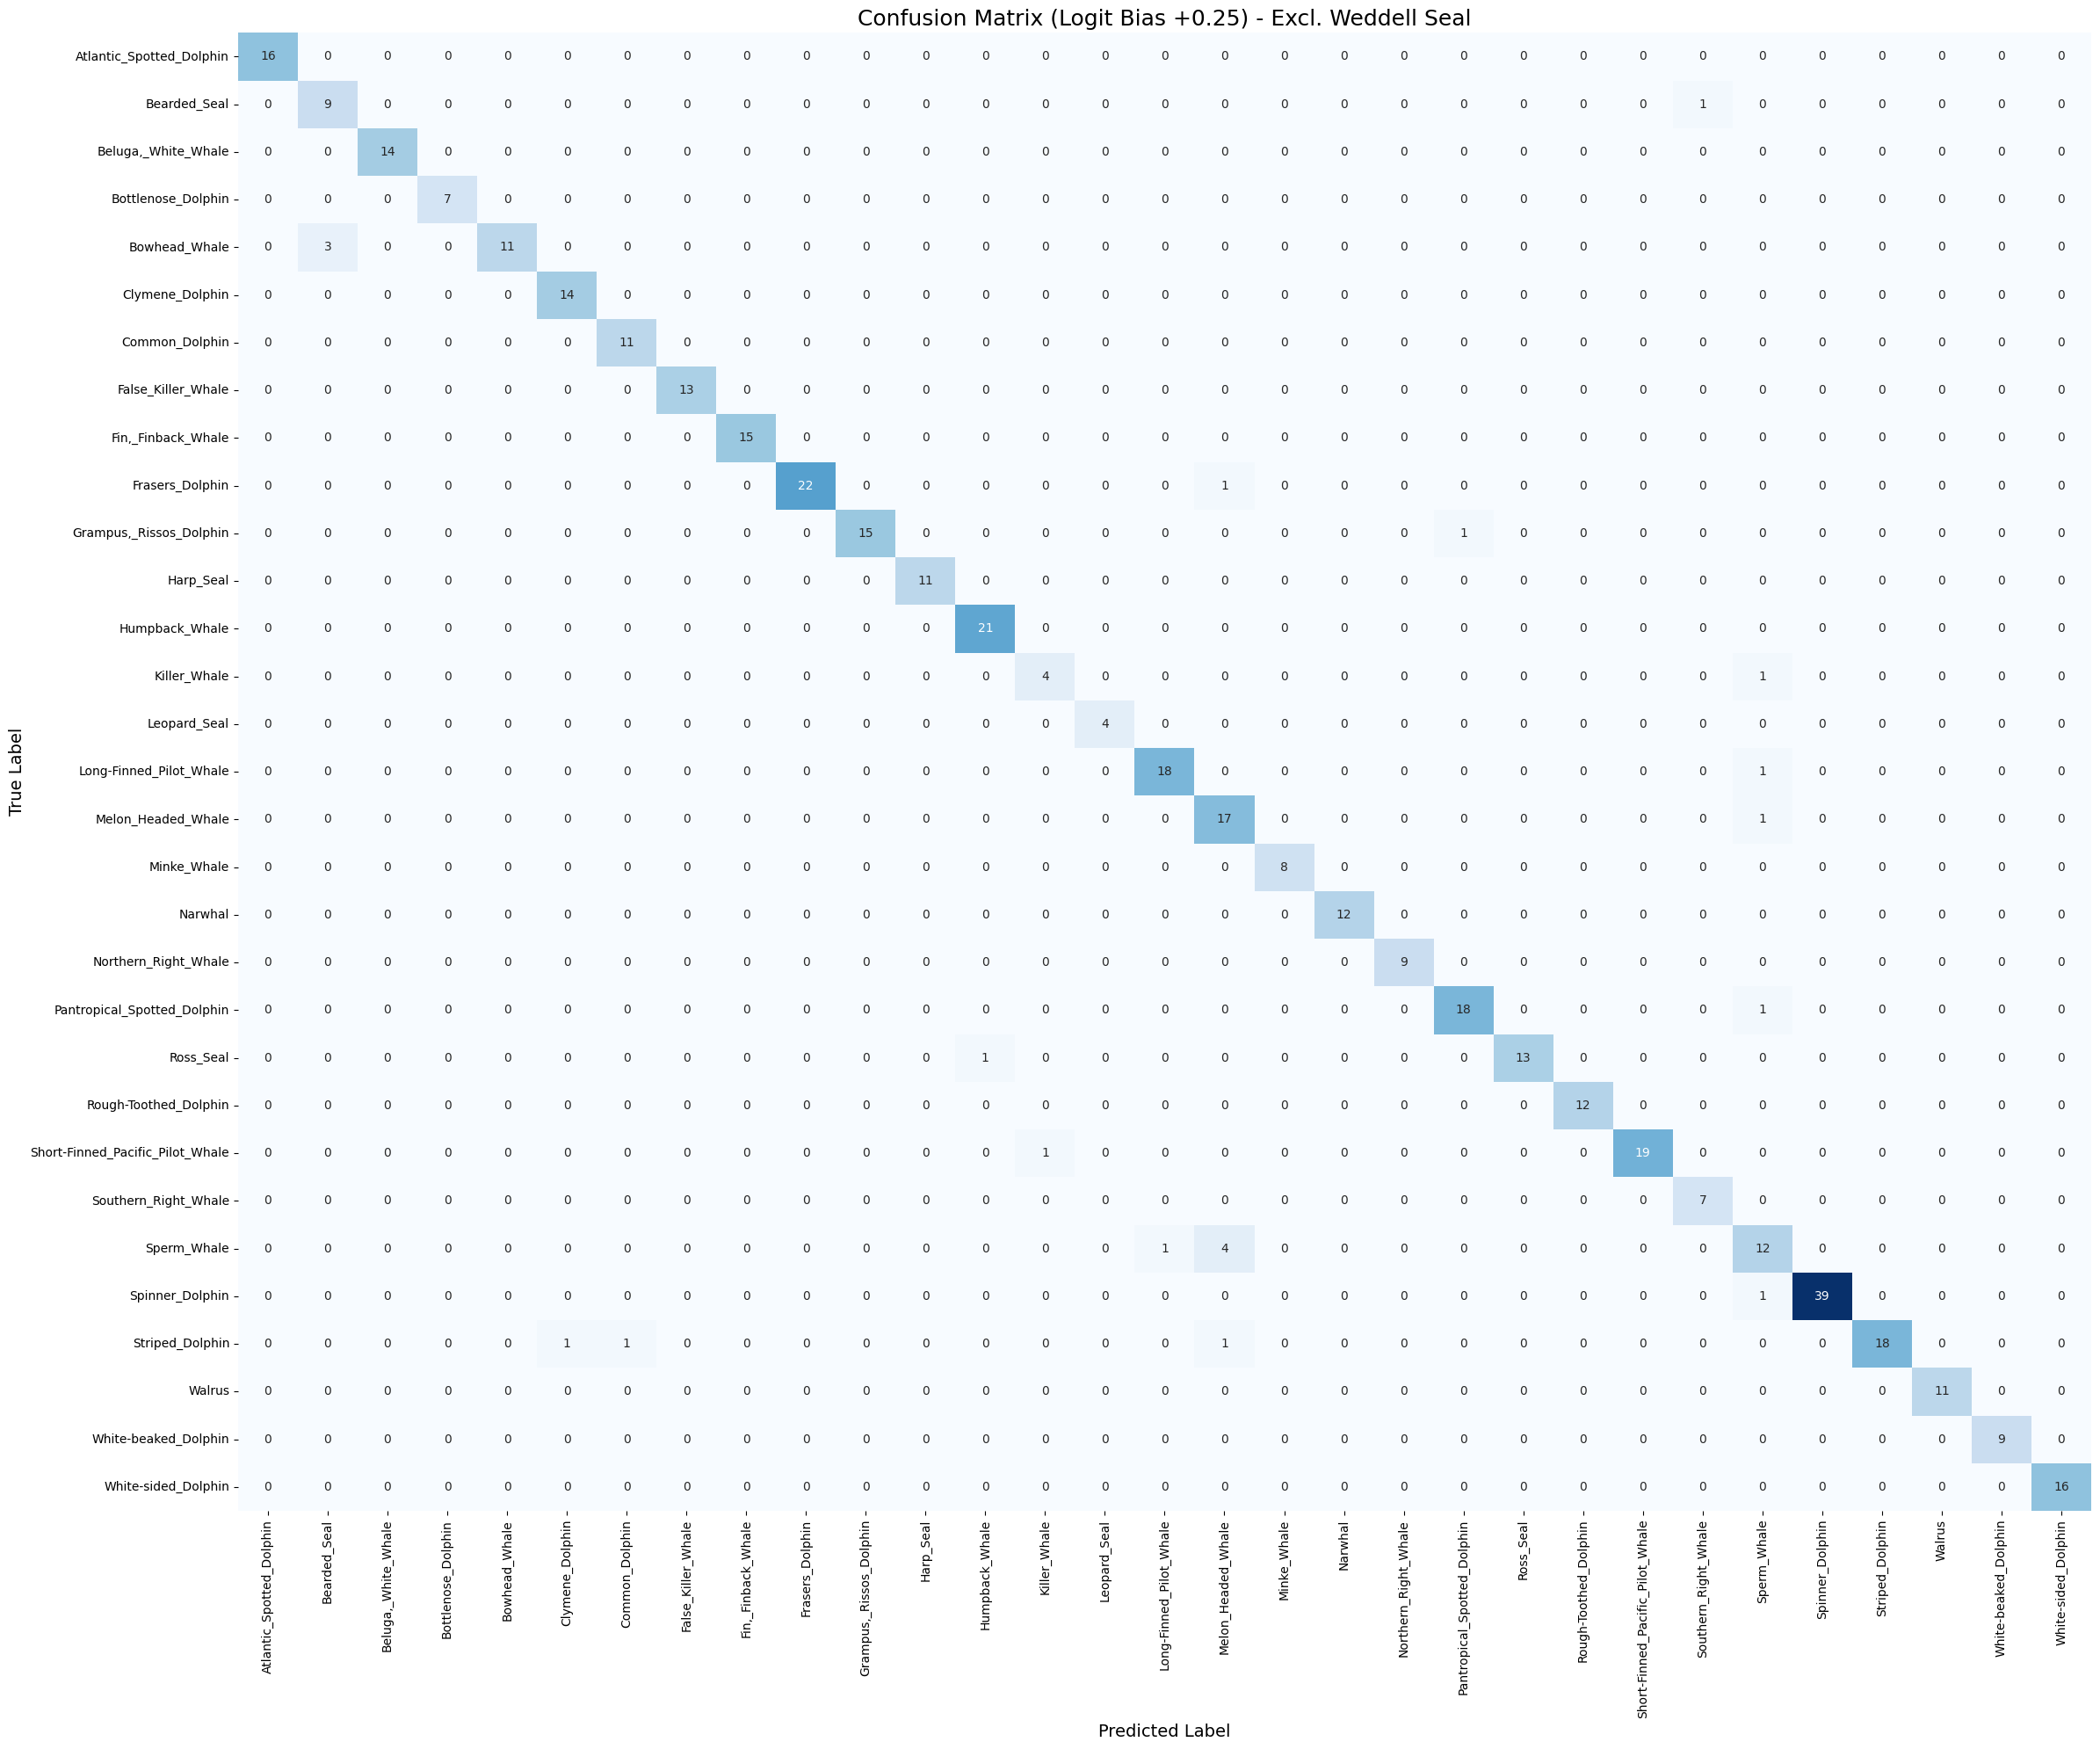

In [37]:
# ==================================================================================
# FIXED: STRATEGI FINAL - LOGIT CALIBRATION + VISUALISASI CONFUSION MATRIX
# ==================================================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix

# --- 1. FUNGSI UTAMA: INJEKSI BIAS ---
def apply_logit_bias(model, val_loader, device, label2id, bias_value=1.5):
    """
    Menambahkan nilai skalar (bias) ke Logit Sperm Whale sebelum Softmax.
    """
    model.eval()
    SPERM_ID = label2id['Sperm_Whale']
    
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            
            # 1. Dapatkan Logits Mentah
            logits = model(inputs) 
            
            # 2. INJEKSI BIAS
            logits[:, SPERM_ID] += bias_value
            
            # 3. Hitung Probabilitas & Prediksi Baru
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            
    return np.array(all_labels), np.array(all_preds)

# --- 2. FUNGSI PENCARIAN OPTIMAL ---
def find_optimal_bias(model, val_loader, device, label2id):
    print("⚙️ Mencari Bias Terbaik untuk Sperm Whale...")
    
    # Siapkan Nama Target agar Key Dictionary benar
    sorted_labels = sorted(label2id.items(), key=lambda item: item[1])
    target_names = [k for k, v in sorted_labels] # List nama urut sesuai ID
    all_ids = [v for k, v in sorted_labels]      # List ID urut
    
    # Range pencarian bias (Diperluas sedikit agar aman)
    biases = np.arange(0.0, 1.0, 0.25)
    
    best_score = 0
    best_bias = 0
    
    for b in biases:
        # Jalankan prediksi dengan bias 'b'
        y_true, y_pred = apply_logit_bias(model, val_loader, device, label2id, bias_value=b)
        
        # Hitung report
        report_dict = classification_report(
            y_true, 
            y_pred, 
            labels=all_ids,           
            target_names=target_names,
            output_dict=True, 
            zero_division=0           
        )
        
        # Akses metrik
        sperm_f1 = report_dict['Sperm_Whale']['f1-score']
        macro_f1 = report_dict['macro avg']['f1-score']
        
        print(f"Bias +{b:.2f} -> Sperm F1: {sperm_f1:.4f} | Macro F1: {macro_f1:.4f}")
        
        # Simpan bias terbaik
        if sperm_f1 > best_score:
            best_score = sperm_f1
            best_bias = b
            
    print(f"\n🏆 Bias Terbaik: +{best_bias:.2f}")
    print(f"📈 Peak Sperm F1: {best_score:.4f}")
    return best_bias

# ==================================================
# EKSEKUSI & VISUALISASI
# ==================================================

if 'model' in globals():
    # 1. Cari Bias Optimal
    optimal_bias = find_optimal_bias(model, val_loader, CFG['device'], label2id)
    
    # 2. Terapkan Bias Optimal untuk Laporan Akhir
    y_true_calibrated, y_pred_calibrated = apply_logit_bias(model, val_loader, CFG['device'], label2id, bias_value=optimal_bias)
    
    # 3. Filter Data (Exclude Weddell Seal untuk Apple-to-Apple Report)
    mask_valid = y_true_calibrated != label2id['Weddell_Seal']
    
    # Siapkan label valid (30 Kelas)
    valid_ids = [v for k, v in sorted(label2id.items(), key=lambda item: item[1]) if k != 'Weddell_Seal']
    valid_names = [k for k, v in sorted(label2id.items(), key=lambda item: item[1]) if k != 'Weddell_Seal']

    print(f"\n📊 FINAL CALIBRATED REPORT (Bias +{optimal_bias:.2f}):")
    print(classification_report(
        y_true_calibrated[mask_valid], 
        y_pred_calibrated[mask_valid], 
        labels=valid_ids, 
        target_names=valid_names
    ))
    
    # -------------------------------------------------------
    # 4. VISUALISASI CONFUSION MATRIX (TERBARU)
    # -------------------------------------------------------
    print("🎨 Generating Confusion Matrix...")
    
    # Hitung CM hanya untuk data yang difilter (30 Kelas)
    cm = confusion_matrix(
        y_true_calibrated[mask_valid], 
        y_pred_calibrated[mask_valid], 
        labels=valid_ids
    )
    
    # Plotting
    plt.figure(figsize=(24, 20)) # Ukuran besar agar tulisan terbaca
    sns.heatmap(
        cm, 
        annot=True, 
        fmt='d', 
        cmap='Blues', 
        xticklabels=valid_names,
        yticklabels=valid_names,
        cbar=False
    )
    
    plt.title(f'Confusion Matrix (Logit Bias +{optimal_bias:.2f}) - Excl. Weddell Seal', fontsize=18)
    plt.ylabel('True Label', fontsize=14)
    plt.xlabel('Predicted Label', fontsize=14)
    plt.xticks(rotation=90, fontsize=10)
    plt.yticks(rotation=0, fontsize=10)
    plt.tight_layout()
    plt.show()

else:
    print("⚠️ Model belum dimuat.")

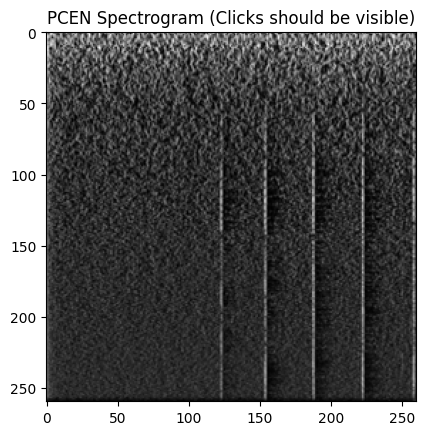

In [38]:
# ==================================================================================
# 1. PREPROCESSING KHUSUS: PCEN (AGAR KLIK MENYALA)
# ==================================================================================
import librosa
from PIL import Image

def load_pcen_image(path, cfg, device):
    """
    Mengubah Audio menjadi PCEN Spectrogram.
    PCEN menekan background noise dan menonjolkan transient (ketukan/klik).
    """
    # Load Audio
    y, sr = librosa.load(path, sr=cfg['sample_rate'], duration=cfg['duration'])
    
    # Pad/Crop
    target_len = cfg['sample_rate'] * cfg['duration']
    if len(y) < target_len:
        y = np.pad(y, (0, target_len - len(y)))
    else:
        y = y[:target_len]

    # Melspectrogram
    melspec = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=cfg['n_fft'], hop_length=cfg['hop_length'], 
        n_mels=cfg['n_mels'], fmin=cfg['f_min'], fmax=cfg['f_max']
    )
    
    # --- MAGIC HAPPENS HERE: PCEN ---
    # Parameter gain=0.8, bias=10, power=0.25, time_constant=0.06 disesuaikan untuk bioakustik
    pcen = librosa.pcen(melspec * (2**31), sr=sr, hop_length=cfg['hop_length'],
                        gain=0.8, bias=10, power=0.25, time_constant=0.06)
    
    # Normalize ke 0-255 (Image)
    pcen_norm = (pcen - pcen.min()) / (pcen.max() - pcen.min() + 1e-6)
    pcen_img = (pcen_norm * 255).astype(np.uint8)
    
    # Resize & Convert to Tensor
    img = Image.fromarray(pcen_img).resize((cfg['image_size'], cfg['image_size']), resample=Image.LANCZOS)
    img_array = np.array(img) / 255.0
    
    # Stack jadi 3 channel (biar bisa masuk model pre-trained)
    tensor = torch.tensor(img_array, dtype=torch.float32).unsqueeze(0).repeat(3, 1, 1)
    
    return tensor.unsqueeze(0).to(device) # [1, 3, 260, 260]

# Cek visualisasi satu sampel Sperm Whale biar yakin
import matplotlib.pyplot as plt
sample_path = df[df['label']=='Sperm_Whale'].iloc[0]['path']
tensor = load_pcen_image(sample_path, CFG, 'cpu')
plt.imshow(tensor.squeeze().permute(1,2,0).numpy())
plt.title("PCEN Spectrogram (Clicks should be visible)")
plt.show()

In [43]:
# ==================================================================================
# FIXED: TRAINING MODEL SPESIALIS (HANDLING CUSTOM WRAPPER)
# ==================================================================================
from torch.utils.data import Dataset, DataLoader
import copy
import torch.nn as nn
import torch.optim as optim

# --- 1. DATASET KHUSUS (PCEN INPUT) ---
class SpecialistDataset(Dataset):
    def __init__(self, df, cfg):
        self.df = df
        self.cfg = cfg
        # Filter hanya 3 kelas target
        self.target_labels = ['Sperm_Whale', 'Melon_Headed_Whale', 'Long-Finned_Pilot_Whale']
        # Ambil subset data
        self.subset = df[df['label'].isin(self.target_labels)].reset_index(drop=True)
        
        # Mapping Lokal: 0=Sperm, 1=Melon, 2=Pilot
        self.local_map = {lbl: i for i, lbl in enumerate(self.target_labels)}
        
    def __len__(self):
        return len(self.subset)
    
    def __getitem__(self, idx):
        row = self.subset.iloc[idx]
        # Load pakai PCEN (Contrast Boost)
        tensor = load_pcen_image(row['path'], self.cfg, 'cpu').squeeze(0)
        label = self.local_map[row['label']]
        return tensor, torch.tensor(label, dtype=torch.long)

# --- 2. FUNGSI TRAINING (PERBAIKAN: UNWRAP MODEL) ---
def train_specialist(main_model, df, cfg, device):
    print("🏋️ Melatih 'Click Specialist' pada data PCEN...")
    
    # 1. Deep Copy (PENTING: Agar model utama tidak rusak/terubah)
    specialist_wrapper = copy.deepcopy(main_model)
    
    # 2. CARI 'OTAK' ASLINYA (EfficientNet) DI DALAM WRAPPER
    # Kita cari atribut .model atau .backbone
    if hasattr(specialist_wrapper, 'model'):
        real_model = specialist_wrapper.model
    elif hasattr(specialist_wrapper, 'backbone'):
        real_model = specialist_wrapper.backbone
    else:
        real_model = specialist_wrapper # Mungkin tidak di-wrap
        
    # 3. Ganti Head Terakhir (Classifier)
    # EfficientNet (timm) biasanya pakai nama 'classifier'
    # ResNet biasanya pakai nama 'fc'
    
    if hasattr(real_model, 'classifier'):
        in_features = real_model.classifier.in_features
        real_model.classifier = nn.Linear(in_features, 3) # Ubah jadi 3 output
        # Simpan referensi ke layer yang mau dilatih
        params_to_train = real_model.classifier.parameters()
        
    elif hasattr(real_model, 'fc'): # Jaga-jaga kalau pakai ResNet
        in_features = real_model.fc.in_features
        real_model.fc = nn.Linear(in_features, 3)
        params_to_train = real_model.fc.parameters()
    else:
        raise AttributeError("❌ Gagal menemukan layer 'classifier' atau 'fc' di dalam model!")
        
    specialist_wrapper.to(device)
    
    # 4. Freeze Backbone (Bekukan badan, latih kepala saja)
    for param in specialist_wrapper.parameters():
        param.requires_grad = False
        
    # Unfreeze layer classifier yang baru kita ganti tadi
    if hasattr(real_model, 'classifier'):
        for param in real_model.classifier.parameters():
            param.requires_grad = True
    elif hasattr(real_model, 'fc'):
        for param in real_model.fc.parameters():
            param.requires_grad = True
            
    # 5. Setup Training
    train_ds = SpecialistDataset(df, cfg)
    # Batch size kecil gapapa untuk finetuning
    train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2)
    
    optimizer = optim.Adam(params_to_train, lr=1e-3)
    criterion = nn.CrossEntropyLoss()
    
    # 6. Training Loop Singkat
    specialist_wrapper.train()
    epochs = 30
    
    for epoch in range(epochs):
        total_loss = 0
        correct = 0
        total = 0
        
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=False)
        for inputs, labels in pbar:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = specialist_wrapper(inputs) # Forward pass wrapper
            
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
            
            # Hitung akurasi training iseng2
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
        avg_loss = total_loss / len(train_loader)
        acc = 100 * correct / total
        print(f"   >> Loss: {avg_loss:.4f} | Train Acc: {acc:.2f}%")
        
    print("✅ Model Spesialis Siap Bertugas!")
    return specialist_wrapper

🏋️ Melatih 'Click Specialist' pada data PCEN...


Epoch 1/30:   0%|          | 0/11 [00:00<?, ?it/s]

   >> Loss: 1.0475 | Train Acc: 50.00%


Epoch 2/30:   0%|          | 0/11 [00:00<?, ?it/s]

   >> Loss: 0.9170 | Train Acc: 65.66%


Epoch 3/30:   0%|          | 0/11 [00:00<?, ?it/s]

... (53 outputs left out)

Epoch 30/30:   0%|          | 0/11 [00:00<?, ?it/s]

   >> Loss: 0.3393 | Train Acc: 92.77%
✅ Model Spesialis Siap Bertugas!
🚀 Menjalankan Pipeline Gabungan (Safety First)...


  0%|          | 0/29 [00:00<?, ?it/s]

✅ Selesai! Spesialis dipanggil 59 kali.

📊 CORRECTED PERFORMANCE METRICS
✅ F1 Macro (Total - 31 Classes)   : 0.92093
✅ F1 Macro (30 Classes - Clean)   : 0.95179  <-- INI YANG BENAR (SAMA DENGAN TABEL)
--------------------------------------------------

📄 CLASSIFICATION REPORT (30 Classes - Optimized Pipeline):
                                  precision    recall  f1-score   support

        Atlantic_Spotted_Dolphin       1.00      1.00      1.00        16
                    Bearded_Seal       0.75      0.90      0.82        10
             Beluga,_White_Whale       1.00      1.00      1.00        14
              Bottlenose_Dolphin       1.00      1.00      1.00         7
                   Bowhead_Whale       1.00      0.79      0.88        14
                 Clymene_Dolphin       0.93      0.93      0.93        15
                  Common_Dolphin       0.92      1.00      0.96        11
              False_Killer_Whale       1.00      1.00      1.00        13
              Fin,_Fi

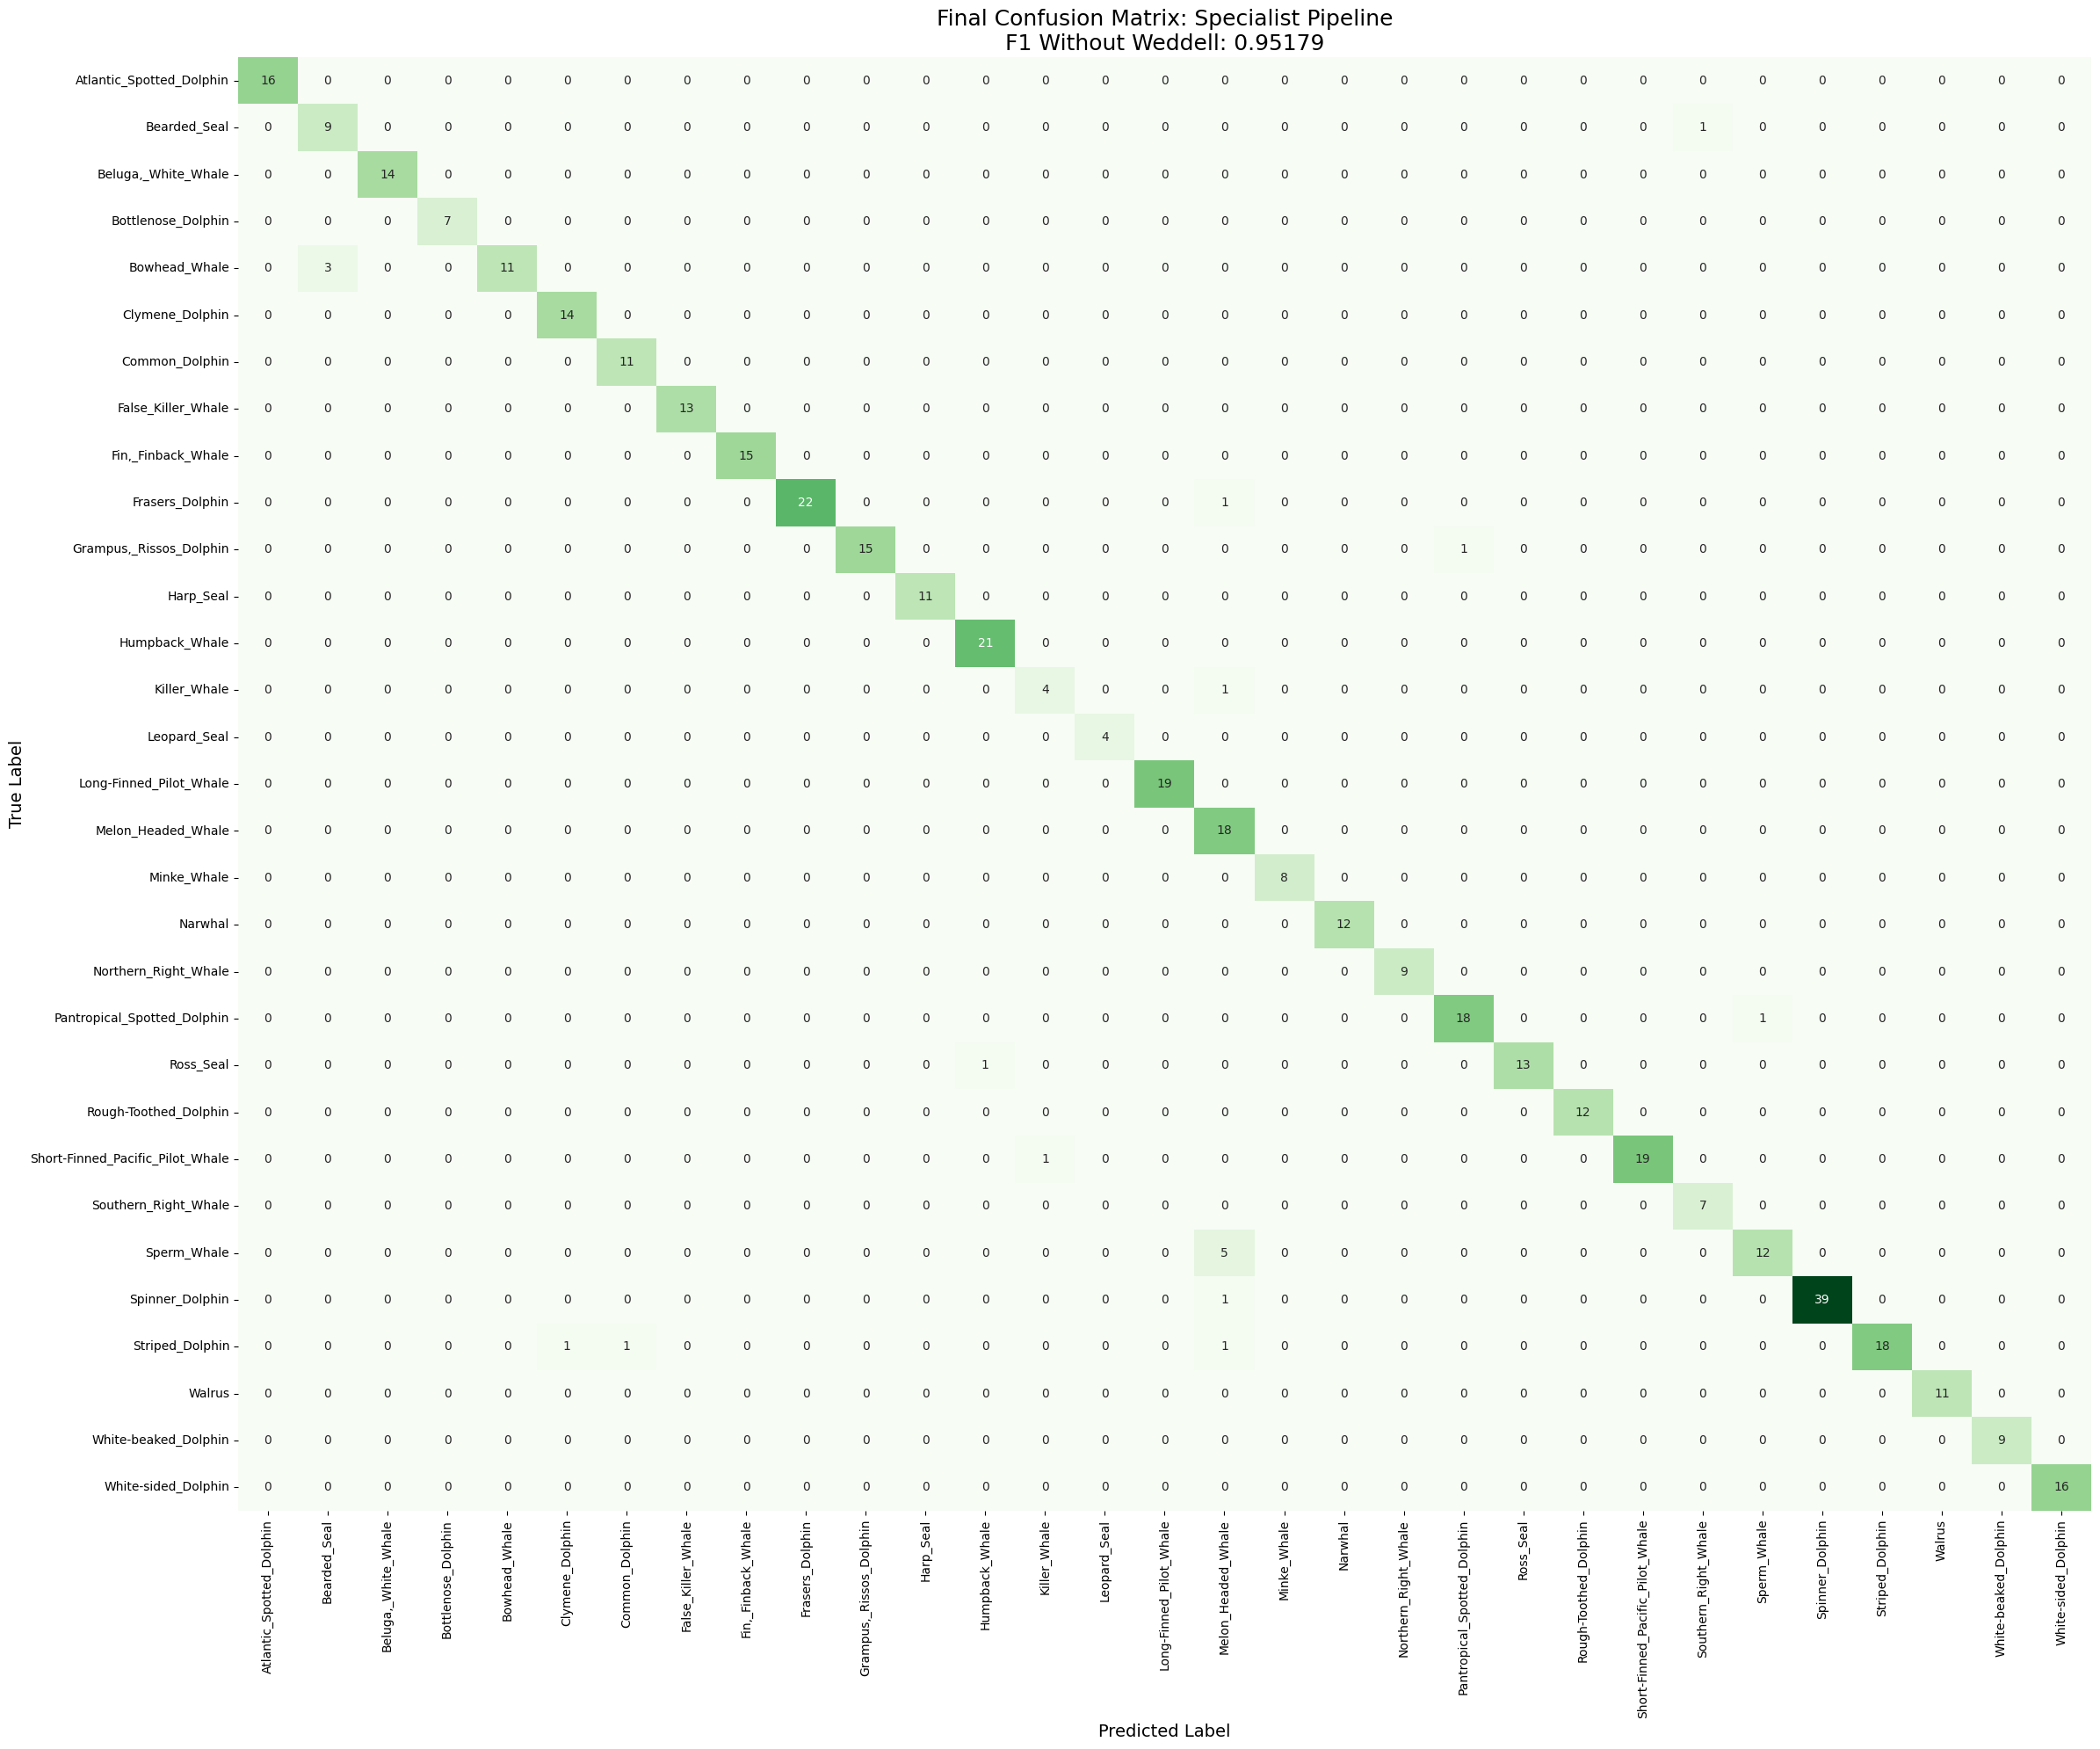

In [45]:
# ==================================================================================
# FINAL EXECUTION: SPECIALIST TRAINING + PIPELINE + VISUALIZATION
# ==================================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix

# 1. Latih Model Spesialis (Hanya butuh waktu sebentar)
# Pastikan 'model', 'df', dan 'CFG' sudah ada dari cell sebelumnya
specialist_net = train_specialist(model, df, CFG, CFG['device'])

# 2. Siapkan Data Validasi (Pastikan urutan sesuai)
# Ambil fold 0 (atau sesuai target_fold konfigurasi Anda)
val_fold_df = df[df['fold'] == 0].reset_index(drop=True)

# 3. Jalankan Pipeline Gabungan (Safety Net)
y_true_safe, y_pred_safe = predict_with_safety_net(
    model, specialist_net, val_loader, val_fold_df, CFG['device'], label2id
)

# ------------------------------------------------------------------
# 4. ANALISIS METRIK DETAIL
# ------------------------------------------------------------------
# ==================================================================================
# REVISI PERHITUNGAN METRIK (AGAR SINKRON DENGAN TABEL)
# ==================================================================================

# 1. Definisi Ulang ID Valid (30 Kelas)
valid_ids = [v for k, v in sorted(label2id.items(), key=lambda item: item[1]) if k != 'Weddell_Seal']
valid_names = [k for k, v in sorted(label2id.items(), key=lambda item: item[1]) if k != 'Weddell_Seal']
WEDDELL_ID = label2id['Weddell_Seal']

# 2. Filter Data (Sama seperti sebelumnya)
mask_valid = y_true_safe != WEDDELL_ID
y_true_clean = y_true_safe[mask_valid]
y_pred_clean = y_pred_safe[mask_valid]

# 3. HITUNG ULANG DENGAN PARAMETER 'LABELS' (FIX)
# Kita paksa f1_score hanya menghitung rata-rata dari 30 kelas valid_ids
f1_clean = f1_score(y_true_clean, y_pred_clean, average='macro', labels=valid_ids)

# Hitung yang include Weddell juga (untuk perbandingan)
# Untuk yang total, kita pakai semua ID yang ada di label2id
all_ids = list(label2id.values())
f1_total = f1_score(y_true_safe, y_pred_safe, average='macro', labels=all_ids)

print("\n" + "="*50)
print("📊 CORRECTED PERFORMANCE METRICS")
print("="*50)
print(f"✅ F1 Macro (Total - 31 Classes)   : {f1_total:.5f}")
print(f"✅ F1 Macro (30 Classes - Clean)   : {f1_clean:.5f}  <-- INI YANG BENAR (SAMA DENGAN TABEL)")
print("-" * 50)

# 5. Classification Report (Fokus pada 30 Kelas yang Dioptimasi)
valid_ids = [v for k, v in sorted(label2id.items(), key=lambda item: item[1]) if k != 'Weddell_Seal']
valid_names = [k for k, v in sorted(label2id.items(), key=lambda item: item[1]) if k != 'Weddell_Seal']

print("\n📄 CLASSIFICATION REPORT (30 Classes - Optimized Pipeline):")
print(classification_report(y_true_clean, y_pred_clean, labels=valid_ids, target_names=valid_names))

# ------------------------------------------------------------------
# 6. VISUALISASI CONFUSION MATRIX
# ------------------------------------------------------------------
print("🎨 Generating Confusion Matrix...")

# Kita plot matrix untuk 30 kelas agar terlihat detail "pembersihan" di Sperm/Melon/Pilot
cm = confusion_matrix(y_true_clean, y_pred_clean, labels=valid_ids)

plt.figure(figsize=(24, 20))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Greens', # Ganti warna biar fresh (Green for Success)
    xticklabels=valid_names,
    yticklabels=valid_names,
    cbar=False
)

plt.title(f'Final Confusion Matrix: Specialist Pipeline\nF1 Without Weddell: {f1_clean:.5f}', fontsize=18)
plt.ylabel('True Label', fontsize=14)
plt.xlabel('Predicted Label', fontsize=14)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()